# Heart Disease: Complete Machine Learning Pipeline
**Muhammad Huzaifa Ali | SP24-BAI-034 | AIC354**

This is a complete, independent version-1 notebook for Jupyter or Google Colab.
Run all cells in order. It fetches its dataset and includes an identical compressed
snapshot as an offline fallback, so no ZIP, helper script, configuration file,
trained model, or manual dataset upload is needed.

**Scope:** reproduce the results already obtained, rather than report new improvements.
Heart Disease retains cp, thalach, oldpeak, and thal; this is the baseline for later improvements.
The existing test results are already known. Rerunning this notebook reproduces
that experiment; it does not create a new independent evaluation.

Outputs are saved automatically to `heart_pipeline_output/` in the current
working directory. Colab output files are temporary unless downloaded.
The evaluated pipeline is saved for deployment without an accuracy gate or full-data refit.
**Live URL: pending Streamlit account sign-in and publication.**

Teaching-code attribution: [haqnawaz99/ml-teaching-notebooks](https://github.com/haqnawaz99/ml-teaching-notebooks),
revision `c5f67db8361bd8953c4facf9e5ab98ce9242f314`.
The original credits Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab.

## Phase 0 - Set up the environment
Tested with Python 3.12. The next cell installs missing or mismatched packages
for reproducibility. If it asks for a restart, choose **Runtime > Restart session**
in Colab or **Kernel > Restart Kernel** in Jupyter, then run all cells again.
A restart is needed only when a changed package was already loaded.

In [1]:
import sys
import subprocess
import importlib
import importlib.metadata

REQUIRED_VERSIONS = {'numpy': '2.3.5', 'scipy': '1.17.0', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8', 'joblib': '1.5.3'}
module_names = {'scikit-learn': 'sklearn'}
changes = []
for package, wanted in REQUIRED_VERSIONS.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != wanted:
        changes.append(f'{package}=={wanted}')
if changes:
    print('Installing:', ', '.join(changes))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *changes])
    importlib.invalidate_caches()
    changed_names = [item.split('==')[0] for item in changes]
    if any(module_names.get(name, name) in sys.modules for name in changed_names):
        raise RuntimeError('Setup complete. Restart the kernel/session once, then run all cells again.')
print('Required packages are available. Python:', sys.version.split()[0])

Required packages are available. Python: 3.12.14


In [2]:
from pathlib import Path
import hashlib
import json
import platform
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer,
                             roc_auc_score, RocCurveDisplay)


TASK = 'heart'
ROOT = Path.cwd() / 'heart_pipeline_output'
for folder in ['data/raw', 'data/prepared', 'reports', 'artifacts']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
PLAN = {'seed': 42, 'test_size': 0.2, 'cv_folds': 5,
        'heart_features': ['cp', 'thalach', 'oldpeak', 'thal']}
SEED = PLAN['seed']
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'joblib': joblib.__version__}
print('Environment:', VERSIONS)
print('Output folder:', ROOT)

Environment: {'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'joblib': '1.5.3'}
Output folder: /workspace/scratch/2c55bf74ebc6/evaluated_release/notebooks/heart_pipeline_output


## Phase 1 - Fetch the dataset
    Download the original data and verify its SHA-256 fingerprint. If internet
    access fails or the remote content changes, use the embedded exact snapshot
    and report the fallback. The snapshot contains data only, not predictions.

Source: [UCI Heart Disease dataset 45](https://archive.ics.uci.edu/dataset/45/heart+disease), processed Cleveland file. Dataset credit: Janosi, Steinbrunn, Pfisterer, and Detrano.

In [3]:
import urllib.request
import zipfile
import io
import base64
import gzip

DATA_URL = 'https://archive.ics.uci.edu/static/public/45/heart+disease.zip'
EXPECTED_SHA256 = 'a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8'
RAW_PATH = ROOT / 'data/raw' / 'processed.cleveland.data'
# Embedded compressed copy allows the notebook to run without data upload.
SNAPSHOT_GZIP_BASE64 = 'H4sIAAAAAAACA5Vc23IjKwx8z7dsbaELl3na//+r4wxjUEvCyXnIbuIyhgGp1WoJN/lb/tD7R+vrX5b3a/z9fy2vf8v9l/yR5/f2/f9X688b9fv/dr9ptPX212tlrI+v9yvy/LAbzPcQvuzg+6+5jna/8v1zj/qS9+B7qXIPWQv9/qHRn9/kNbOs37+XrWRnmYOL2tc6vz/mr/4hGFyb3Zy5bGl25j7WX8MNbu/PvZ9Z78Ft2JlbWQPa3Kj3pn3VbgffM0tVO3N7H1x5DXYzi93tZ8PgmbWbZ+bn3f0+qgqD57ILGkld50Frt+dR1R4G08V22bo3bM68LayCNc2ZL1h2lbVsWYPdUVkjgeNTNhv2/r3dz6waz7kJnDP8ZZ75NTPbmW9rousyb6O2d6D6wWDbdb59wMy6ZvXnrMMum9Cr8KPeU5ij0njOgoP383I2c8Hd7tUONh8VBl922XNwQ6+i9VewbbUYNp+ZwMd1v2N4I7HbMXebB9h2Y/uOONgZydDUn/3MtAfPDbsBjhGGNm7xmqbfYNBK9OcCziK81qaAnvpVi13IXDbBOZtdaacN24NFAXo7J47xHFWLu81wzrR3oHncBhiagxdqoZGQ8apnMGwYTWvudsPIejwbx3jt9mWXnTlGJXPOZHC7uKOiG1KlABhs61I4Z962LWtmkZoeld/tl4VdYCQzuGPEIANDDDCkGtFTEAA3ovkouYDVIAmfoqQ3Ejxnnm+Ho+Kyjqq6o8JwM42kg2PQCfRfG1Zhw+4zrPDMy6u+AdBGyZeRUMBtVrHnvFgLGQt7jKTa4P44Rg3mWcxgWf6sBUhcWeEGd5scoZnn3CnglRTwYBOr1Nn2sjDzzGZ/v1/rx1i1jG9jmEiB1Vxn2wb0vOdkN3hvX4WjegEgHNUEA4xVLMdwU0sCQwLmOQyGWfPUfc7bn5U6UKnu6CPtmSW4JF04mE18/sR6y23p10iZgTUnY54nlyzrUYoDA4ckuo/qKimJ8zN7HiYYq+7XxhlJsiiJcxlmoGvmjA3dkXlzkrmJm7UgGNA2EjERQwJZLw6G5mClGKtWUOUj6Ltlz/h8g34H86yWewpaGFkkmYMJbbsmG2YGO38u4FXq0bOsQKcNHIMj6EOUlJyH6XI/JmRD5I5KcMM2ca33stViWC9HC3NGUqJBkhzzKjTPmXwPOGfdJG4AiTODt4XRgIhRLdY47qkRt4VT9LS43RH0dW2OcEzU5scr5BjPOfuZCYykmxQYl43oeT8fY4zQD8k3Cg51pcCUuCTDbsvM3J1a0SwArvSO3EmRA8+Zn+g4uHNbYDcpiQPPjfk7S+gH8PT7NWN7Q+Sl836VZL9g2UrOOg3+UYhzUkYwbcvV6ZDETthWMO1R3EmdsOAhgPDMtBO5AaYtXwpHdaMAu2Vb3uFmloB/3FBjkUTpmIPlikSfIWSPD2kVkKExn1mDikcuoXsYM4ckVrgeErqQuGsS505HFYg+qng3bFew7drOyCuQhyaYTzUZ/C8e1IC8CNP2ZF6KOoeTqa5E2zH5L8LIJtveIb2JoHo43dPZV13qGS+p1QGYTecQd5uTKgQZ3HrmKeoqDDbs2QsGTUJ85cqp3JrsNsfIXmtIYcnBX0/yX8K0nVNC4oKzy8gQ/oypNhcu0Kdk4ggd0vZxgr/5zFMYgg0bZ7dABKMZIgH+Rj0OFlTSBsAOg/SYHBXq0+O2bSSe1zHB6OBV86hW3NxhIB+sgJ0ZCYNTZ3CMCjhZ5rJR22lnofeK4jbG48YH82Qn9E7bxgpILQ4Mtm03SghJCRkZGR61ZxZ0jBEFQLVCrxPDgObr5MuA2ovjkVPSaGvyhlSg+Gsysu2SD2vlxDwBei+7A1hKUAT92wiUwMJaEtofMOAI+lANuLrbr73ZbpK6qicoKuWrRplDt7ZNgagn7lxDnKMBM49zoSupGIkUeBQ2lJcw2tSoPGK5ibfFDL9hI8naW8pm7HqemSXAtqJ1rnVoENJQFyoFkLcsBucz2Af/atQ8CbBgHVw12rbbMNqUZEAQMUUfdX6B3PiJ7VhJOIfnhW4zSM0aBhJwawmCcU4/RNgppLVDjiBpiY2xknCmYUiGpjqDsN3k56zdFEBcatMTGtZRI/kefBcjmeGYMak0j1y+OKlzQemZC39mns7AGgVeQGdRfdNlBmWnOCBJTbsghFUUW8lZ5x7co8rhaARXU+gX1Es5qbChknnSV2TinxNnUPKUU1pEDgueSAWMxIiB/pkrhrRp2sD/mh6Pql4WC/r2yIxIsV82btgNJKXaucaZwrWoHTouJJRUUnuiyJe5YSUgLzkU6kkqeLMwVjDPyudaAPahTB0NToA/FE8oFhKwlaRfP7NtNpwXjuoThEEZ9nZ8oZGW2yPnRS5Up6g+QLUcBwr3lOcWeN4zcwMfN1Ev5HMdqPr3sNpORW9/zhgkn5ahK+Swb3UGyzYtiq2slv9dzai8VtkWh0KTzmBSVS7nzrINLEFeV2ATAySU+4UapwK/6OSO2WiHJZlZUgMjJ1qyk4UmzcfspPowtUOVAuO6k9ddbPopL+o9eWa0EZ8XvXdbnSD/9HPo/21P0E3hUGxldjuddM/IJhUVwLPX5KgE+3Z2gsGlhwIb/aJjaPI/xvDsUeifJTPY9uEIXL0SQmJShH1QLZYgajss2vNOSpQzGUlm42jB1qadlk87lF0usruONIb+Ai/ypkn7MpGbirBeKcsvoXKStPCJ60jrCe66+GoKPsTh+KxQ8a4EqO9s4CXyvpc9xkHMIiejzfAq0JtgCC9BMldczj6zPuxyKjsMkmup0FizFhRmTX/V9XPBmxGXQhOenGQ0hf1CAldiG0mD1FnvNDJqM/QsG3FXITbrJDOYj3n1j0/sb8T6he60noEuFy9aDijBsuv48TSqSazhXfUjE+LY8WNSKoU0/VLzzG7ZcKYNA3uBjp9iZp2dmijgXbw6+LYqVBMa9cTXWHbxfbHtIB2yK/LP3O5qv81BM04B7I+307ITLbFFamK+QieIgbDpkv/eT8yx+HFBMlKacUjXtD2SzkFKiy5kfCorwBZkUdhcUIxPyW7BW27RtsZBUOIv5okJabov+LTQE0F58ltC69n2Zo9g9DGXm8vusaHikNeAN1NinPX6nMutwSMp69UPKWjSg8xABLq4muBmjk1j7RelBpGkoNiT5j/XzFuOCNaT4scNSYKorT3BkQfykyaSegVlzQrERghDnr61tH3Ozdm2CTY16X6GdLfWXwphNTHPanuckM1IT/y5/lKCkwHNQklJcWw3HK4RDtNuQZLP0I7GsVsSovOMkQzkGvTUQ21Ok87Bz2m3qV+QkZQkJDYWPQumVEiatvr3U+u0tohhKgcMKxnx9K1ZEoKNJ56SFLnmzP23rQmKhT2OV146n2Eo1p0Zm7ZbP5vnZf6cEc7l7Nfn5oKNBQJp0V3vqc62ThWIZ9FXSOV8r9DjkOACT2UOzNHcnemnfgpj2WhfRlKjrD1q91ZxFAuCcdKhDY6S6whlOOPc0gw2RcxlJ1kRmWXv/tCKlbkGHMw3EdNJ17YxstsnpG462exgdlXnWY3UK0C+ZflbUcJEhDH7na+RYSTJbmNbl+suaPLLo5qFACyi0q6DsmNhLhVMbssUK4QdWv+sfHeFezol6cyiL3zj7KhA3azxUWvQpIpw1ePgBMHclSp3BUN+hr9tEFJ+myLolTSU/bbG1aCVd24YXv4w8k2Dc2YnTTPeIShvpfUwcXKxUyyQdDoIcOw4WClx0UZ0JNdP4eAPb6BtPIXjjL0FpjGB+HhxjvLuUFt0GaEEVD5zbYudlNZQbU7Vkm7H28MYawiQ/rseEo2MFy3KVI5QUvJ9cM6n/E2G9vGKD9XIRwYdVTTlOHO5jlczD9ULXamuE1p1n7o4kaO3kNnQhfGimVTwIHhuWdV1tar8bCRsLiNg+x65ZRvsREF9Ukdsa7jMYMydsS5+B1ihK7104lUh+Wol3vdzlwX3sq+PvaWcXCJr18/wZ3pf8PYG16Q/alYg8Pra88w1LVnbOmjbjMR5Fd4nqFl/1L/vodjItr15XyHbvIH9jeUS9WHOfSqR8mN7qOvcreWXe/3cDweablLFyytwLVYEeYTB728gIGzqamFmQbWAy6Evn3fP4eadhHUAruc60xXDa9EDpUCNl9yN5Vnh557e3Yil8oYgdB9+H4cLPsV5MyRF7zpTOdbZ+QMIVU1ujeg5cx6BzGzsLE7Aa6eZd4x012ChzsA5L5DTLbBPmWANXa1cqn1CaIo7NKDswqP77oMP/bTOq0bsGwxKmOktBV5wCyu7t4CAkehzR0d2pQmOqu/LqBQ6PO29pIYzb5B1FmZYvhpp2n+3hmDXDB/5bj9+MQeGGogWknNWk/xiCmrgLzS+1JCrCoZXc+39eIHC9Ci5K01q9log1LT4xRz7i0+wm1YdaWWnU7AmDtmOZVBMirg4vvdZE0JBaYJht8d3eTbxNi//LSgz1uBVBJZEyjcFa/dNEQhZwoemGdrdFFvindIfBQom7isX2DcHeLx7k+D8ZjneiZESyxcAI5jYyAidBa6LIdRQ350F/wGGxfShHUgAAA=='
if RAW_PATH.exists() and hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == EXPECTED_SHA256:
    raw_bytes = RAW_PATH.read_bytes()
    print('Using previously verified dataset.')
else:
    try:
        with urllib.request.urlopen(DATA_URL, timeout=20) as response:
            downloaded = response.read()
        with zipfile.ZipFile(io.BytesIO(downloaded)) as archive:
            raw_bytes = archive.read('processed.cleveland.data')
        if hashlib.sha256(raw_bytes).hexdigest() != EXPECTED_SHA256:
            raise ValueError('Remote dataset differs from the verified version.')
        print('Dataset fetched from original source.')
    except Exception as error:
        print('Download unavailable:', type(error).__name__)
        print('Using the embedded, verified dataset snapshot.')
        raw_bytes = gzip.decompress(base64.b64decode(SNAPSHOT_GZIP_BASE64))
    RAW_PATH.write_bytes(raw_bytes)
assert hashlib.sha256(raw_bytes).hexdigest() == EXPECTED_SHA256
print('Verified dataset:', RAW_PATH.name, '| bytes:', len(raw_bytes))

Using previously verified dataset.
Verified dataset: processed.cleveland.data | bytes: 18461


## Phase 2 - Understand, validate, and prepare the dataset

The Cleveland dataset contains 303 records. Use exactly four raw inputs:
- cp: chest pain category (1 typical angina; 2 atypical angina; 3 non-anginal; 4 asymptomatic).
- thalach: maximum exercise heart rate, in beats per minute.
- oldpeak: exercise-induced ST depression relative to rest.
- thal: thallium test result (3 normal; 6 fixed defect; 7 reversible defect).

Convert num = 0 to absence (0), and num = 1-4 to presence (1).
Replace '?' with missing values. Imputation is fitted later inside training folds.
This is an educational classifier of recorded disease status, not future risk.

In [4]:
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
data = pd.read_csv(RAW_PATH, names=columns, na_values=['?'], header=None)
FEATURES = ['cp', 'thalach', 'oldpeak', 'thal']
NUMERIC, CATEGORICAL = ['thalach', 'oldpeak'], ['cp', 'thal']
CATEGORIES = [[1.0, 2.0, 3.0, 4.0], [3.0, 6.0, 7.0]]
assert len(FEATURES) == 4 and data.shape[1] == 14
assert data['num'].isin([0, 1, 2, 3, 4]).all()
y = (data['num'] > 0).astype(int)
TARGET_NAMES = ['Disease absent', 'Disease present']

X = data.loc[:, FEATURES].copy()
assert y.notna().all() and len(X) == len(y)
for feature, allowed in zip(CATEGORICAL, CATEGORIES):
    assert X[feature].dropna().isin(allowed).all(), f'Unexpected category in {feature}'
print('Records:', len(X), '| input attributes:', FEATURES)
print('Target counts:', y.value_counts().sort_index().to_dict())
print('Missing inputs:', X.isna().sum().to_dict())
print('Matching full records retained:', int(data.duplicated().sum()))
display(data.head())
prepared = X.copy()
prepared['target'] = y
prepared.to_csv(ROOT / f'data/prepared/{TASK}_selected.csv', index=False)

Records: 303 | input attributes: ['cp', 'thalach', 'oldpeak', 'thal']
Target counts: {0: 164, 1: 139}
Missing inputs: {'cp': 0, 'thalach': 0, 'oldpeak': 0, 'thal': 2}
Matching full records retained: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Phase 3 - Split the data and explore development records
Reserve 20% for final testing using seed 42 and class stratification. Use only
the remaining 80% for model choices and five-fold CV. Descriptive plots below
use development records. This preserves the earlier experiment's exact split.

Development: 242 | locked test: 61


,cp,thalach,oldpeak,thal
count,242.000000,242.000000,242.000000,241.000000
mean,3.152893,149.962810,0.999174,4.713693
std,0.975516,22.686449,1.122940,1.948552
min,1.000000,71.000000,0.000000,3.000000
25%,2.250000,134.500000,0.000000,3.000000
50%,3.000000,153.500000,0.800000,3.000000
75%,4.000000,166.000000,1.600000,7.000000
max,4.000000,202.000000,6.200000,7.000000


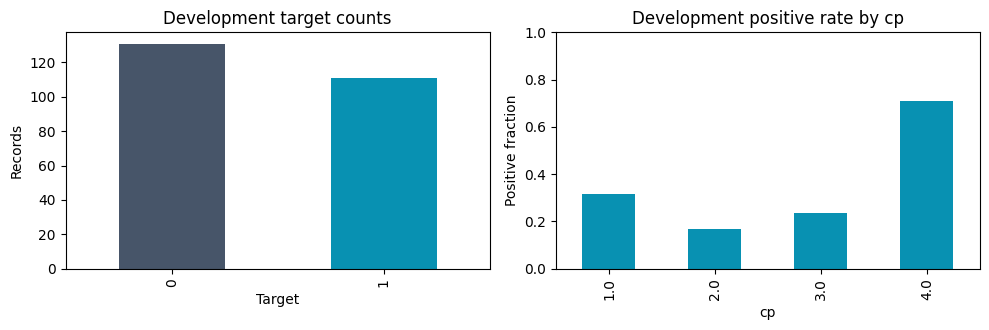

In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=PLAN['test_size'], random_state=SEED, stratify=y, shuffle=True)
split_rows = pd.DataFrame({'row_id': X.index, 'partition': 'development'})
split_rows.loc[split_rows.row_id.isin(X_test.index), 'partition'] = 'test'
split_rows.to_csv(ROOT / f'reports/{TASK}_split.csv', index=False)
print('Development:', len(X_dev), '| locked test:', len(X_test))
display(X_dev.describe(include='all'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
y_dev.value_counts().sort_index().plot.bar(ax=axes[0], color=['#475569', '#0891b2'])
axes[0].set(title='Development target counts', xlabel='Target', ylabel='Records')
view = X_dev.copy()
view['target'] = y_dev
grouping = 'cp'
view.groupby(grouping)['target'].mean().plot.bar(ax=axes[1], color='#0891b2')
axes[1].set(title=f'Development positive rate by {grouping}', ylabel='Positive fraction', ylim=(0, 1))
plt.tight_layout()
plt.savefig(ROOT / f'reports/{TASK}_development.png', dpi=150)
plt.show()

## Phase 4 - Build the preprocessing pipeline
Encode categorical inputs using source-defined category vocabularies.
Impute categorical missing values with the training-fold mode. Numeric inputs,
when present, use median imputation and standard scaling inside the same fold.
One-hot columns represent original inputs; they do not add new raw attributes.

In [6]:
transformers = []
if NUMERIC:
    numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])
    transformers.append(('numeric', numeric_pipeline, NUMERIC))
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(categories=CATEGORIES, handle_unknown='ignore', sparse_output=False))])
transformers.append(('categorical', categorical_pipeline, CATEGORICAL))
preprocessor = ColumnTransformer(transformers, remainder='drop')

## Phase 5 - Train and compare candidate models using cross-validation
Compare a majority-class baseline, SVC, Logistic Regression, and Random Forest.
Report average training accuracy and validation accuracy across the same five
folds. Training accuracy here is the mean across CV training folds, not a
separate score measured on the complete development partition.

In [7]:
candidates = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'SVC': SVC(random_state=SEED),
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=150, max_depth=4,
                                            min_samples_leaf=3, random_state=SEED, n_jobs=1)}
cv = StratifiedKFold(n_splits=PLAN['cv_folds'], shuffle=True, random_state=SEED)
scoring = {'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0), 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc'}
rows, searches = [], {}
started = time.perf_counter()
for name, classifier in candidates.items():
    pipeline = Pipeline([('preprocess', clone(preprocessor)), ('classifier', classifier)])
    scores = cross_validate(pipeline, X_dev, y_dev, cv=cv, scoring=scoring,
                            return_train_score=True, error_score='raise', n_jobs=1)
    rows.append({'model': name, 'stage': 'baseline',
                 'cv_accuracy': scores['test_accuracy'].mean(),
                 'cv_accuracy_std': scores['test_accuracy'].std(),
                 'cv_f1': scores['test_f1'].mean(),
                 'cv_recall': scores['test_recall'].mean(),
                 'cv_roc_auc': scores['test_roc_auc'].mean(),
                 'train_accuracy': scores['train_accuracy'].mean()})
baseline = pd.DataFrame(rows)
display(baseline.round(4))

,model,stage,cv_accuracy,cv_accuracy_std,cv_f1,cv_recall,cv_roc_auc,train_accuracy
0,Dummy,baseline,0.5413,0.0065,0.0000,0.0000,0.5000,0.5413
1,SVC,baseline,0.7770,0.0318,0.7450,0.7119,0.8594,0.8326
2,LogisticRegression,baseline,0.7849,0.0370,0.7583,0.7296,0.8662,0.8047
3,RandomForest,baseline,0.7768,0.0248,0.7426,0.7024,0.8585,0.8399


## Phase 6 - Tune hyperparameters and freeze the selected model
Reproduce the predefined version-1 search: tune SVC; tune the other families
when baseline accuracy is within 0.05 of the best non-dummy baseline.
Selection uses CV accuracy, then F1, then model name for ties. The reserved
test set is not used for this selection. These are tuning-CV scores; broader
future feature searches should use nested CV for evaluation of the search.

In [8]:
grids = {
    'SVC': [
        {'classifier__kernel': ['linear'], 'classifier__C': [0.1, 1, 10, 100],
         'classifier__class_weight': [None, 'balanced']},
        {'classifier__kernel': ['rbf'], 'classifier__C': [0.1, 1, 10, 100],
         'classifier__gamma': ['scale', 0.01, 0.1, 1],
         'classifier__class_weight': [None, 'balanced']}],
    'LogisticRegression': {'classifier__C': [0.1, 1, 10, 100],
                           'classifier__class_weight': [None, 'balanced']},
    'RandomForest': {'classifier__max_depth': [3, 5, None],
                     'classifier__min_samples_leaf': [2, 5],
                     'classifier__class_weight': [None, 'balanced']}}
strongest = baseline.loc[baseline.model != 'Dummy', 'cv_accuracy'].max()
for name in ['SVC', 'LogisticRegression', 'RandomForest']:
    base_score = float(baseline.loc[baseline.model == name, 'cv_accuracy'].iloc[0])
    if name != 'SVC' and base_score < strongest - 0.05:
        print('Skip tuning', name, ': baseline more than 0.05 below best.')
        continue
    pipeline = Pipeline([('preprocess', clone(preprocessor)),
                         ('classifier', clone(candidates[name]))])
    search = GridSearchCV(pipeline, grids[name], cv=cv, scoring=scoring,
                          refit='accuracy', return_train_score=True, n_jobs=1,
                          error_score='raise')
    search.fit(X_dev, y_dev)
    searches[name] = search
    i = search.best_index_
    rows.append({'model': name, 'stage': 'tuned',
                 'cv_accuracy': search.cv_results_['mean_test_accuracy'][i],
                 'cv_accuracy_std': search.cv_results_['std_test_accuracy'][i],
                 'cv_f1': search.cv_results_['mean_test_f1'][i],
                 'cv_recall': search.cv_results_['mean_test_recall'][i],
                 'cv_roc_auc': search.cv_results_['mean_test_roc_auc'][i],
                 'train_accuracy': search.cv_results_['mean_train_accuracy'][i]})
    pd.DataFrame(search.cv_results_).to_csv(ROOT / f'reports/{TASK}_{name}_search.csv', index=False)
    print(name, 'best params:', search.best_params_)
comparison = pd.DataFrame(rows).sort_values(
    ['cv_accuracy', 'cv_f1', 'model'], ascending=[False, False, True], kind='stable')
comparison.to_csv(ROOT / f'reports/{TASK}_model_comparison.csv', index=False)
display(comparison.round(4))
best_row = comparison.loc[comparison.model != 'Dummy'].iloc[0]
best_name = str(best_row['model'])
if best_row['stage'] == 'tuned':
    selected = clone(searches[best_name].best_estimator_)
else:
    selected = Pipeline([('preprocess', clone(preprocessor)),
                         ('classifier', clone(candidates[best_name]))])
frozen_params = {k: v for k, v in selected.get_params().items()
                 if k.startswith('classifier__') and isinstance(v, (str, int, float, bool, type(None)))}
decision = {'model': best_name, 'stage': str(best_row['stage']),
            'features': FEATURES, 'parameters': frozen_params,
            'cv_accuracy': float(best_row['cv_accuracy']),
            'cv_accuracy_std': float(best_row['cv_accuracy_std']),
            'test_used_for_selection': False}
(ROOT / f'reports/{TASK}_frozen_selection.json').write_text(json.dumps(decision, indent=2))
print('Frozen selection:', decision)
print('Training/search elapsed seconds:', round(time.perf_counter() - started, 2))

SVC best params: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
LogisticRegression best params: {'classifier__C': 10, 'classifier__class_weight': 'balanced'}
RandomForest best params: {'classifier__class_weight': None, 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 2}
Frozen selection: {'model': 'SVC', 'stage': 'tuned', 'features': ['cp', 'thalach', 'oldpeak', 'thal'], 'parameters': {'classifier__C': 1, 'classifier__break_ties': False, 'classifier__cache_size': 200, 'classifier__class_weight': 'balanced', 'classifier__coef0': 0.0, 'classifier__decision_function_shape': 'ovr', 'classifier__degree': 3, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf', 'classifier__max_iter': -1, 'classifier__probability': False, 'classifier__random_state': 42, 'classifier__shrinking': True, 'classifier__tol': 0.001, 'classifier__verbose': False}, 'cv_accuracy': 0.7931972789115647, 'cv_accuracy_std': 0.040283691625826

,model,stage,cv_accuracy,cv_accuracy_std,cv_f1,cv_recall,cv_roc_auc,train_accuracy
4,SVC,tuned,0.7932,0.0403,0.7699,0.7474,0.8731,0.7892
5,LogisticRegression,tuned,0.7892,0.0305,0.7702,0.7656,0.8617,0.8068
2,LogisticRegression,baseline,0.7849,0.0370,0.7583,0.7296,0.8662,0.8047
1,SVC,baseline,0.7770,0.0318,0.7450,0.7119,0.8594,0.8326
6,RandomForest,tuned,0.7769,0.0303,0.7429,0.7028,0.8488,0.8657
3,RandomForest,baseline,0.7768,0.0248,0.7426,0.7024,0.8585,0.8399
0,Dummy,baseline,0.5413,0.0065,0.0000,0.0000,0.5000,0.5413


## Phase 7 - Test the frozen model and show evaluation results
Fit on development records and apply the frozen pipeline to the reserved
records. Calculate accuracy, precision, recall, F1, ROC-AUC, confusion matrix,
and an accuracy interval. Save actual test predictions. Reproduction of a
known split is not a fresh independent test of later model improvements.

Final test accuracy: 53/61 = 86.8852%
95% Wilson interval: [0.762 0.932]
                 precision    recall  f1-score   support

 Disease absent       0.90      0.85      0.88        33
Disease present       0.83      0.89      0.86        28

       accuracy                           0.87        61
      macro avg       0.87      0.87      0.87        61
   weighted avg       0.87      0.87      0.87        61



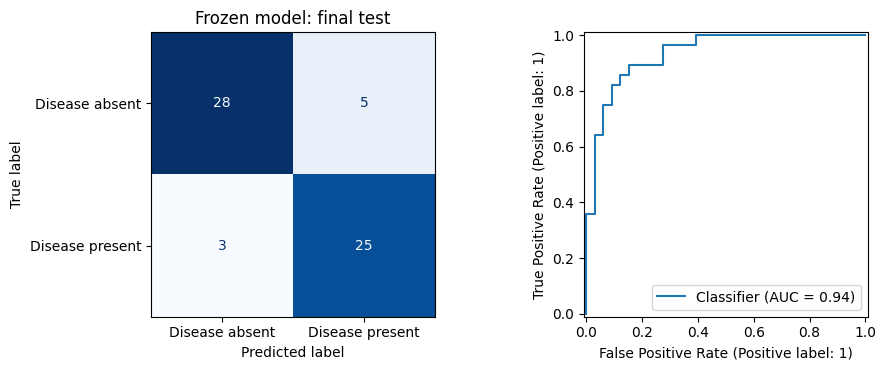

In [9]:
selected.fit(X_dev, y_dev)
test_pred = selected.predict(X_test)
if hasattr(selected, 'decision_function'):
    test_score = selected.decision_function(X_test)
else:
    test_score = selected.predict_proba(X_test)[:, 1]
accuracy = float(accuracy_score(y_test, test_pred))
correct, n = int((y_test.to_numpy() == test_pred).sum()), len(y_test)
z = 1.959963984540054
denominator = 1 + z*z/n
center = (accuracy + z*z/(2*n)) / denominator
half_width = z*np.sqrt(accuracy*(1-accuracy)/n + z*z/(4*n*n)) / denominator
metrics = {'task': TASK, **decision, 'test_accuracy': accuracy,
           'correct': correct, 'test_records': n,
           'test_accuracy_wilson_95': [float(center-half_width), float(center+half_width)],
           'precision': float(precision_score(y_test, test_pred, zero_division=0)),
           'recall': float(recall_score(y_test, test_pred, zero_division=0)),
           'f1': float(f1_score(y_test, test_pred, zero_division=0)),
           'roc_auc': float(roc_auc_score(y_test, test_score)),
           'confusion_matrix': confusion_matrix(y_test, test_pred, labels=[0,1]).tolist(),
           'deployment_policy': 'serve_evaluated_pipeline', 'full_data_refit': False,
           'development_records': len(X_dev), 'total_records': len(X),
           'versions': VERSIONS, 'raw_data_sha256': hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()}
print(f'Final test accuracy: {correct}/{n} = {accuracy:.4%}')
print('95% Wilson interval:', np.round(metrics['test_accuracy_wilson_95'], 4))
print(classification_report(y_test, test_pred, labels=[0,1], target_names=TARGET_NAMES, zero_division=0))
evaluated_path = ROOT / f'artifacts/{TASK}_evaluation.joblib'
joblib.dump(selected, evaluated_path)
metrics['artifact_sha256'] = hashlib.sha256(evaluated_path.read_bytes()).hexdigest()
reloaded = joblib.load(evaluated_path)
np.testing.assert_array_equal(test_pred, reloaded.predict(X_test))
evidence = X_test.copy()
evidence.insert(0, 'row_id', evidence.index)
evidence['actual'], evidence['predicted'], evidence['decision_score'] = y_test, test_pred, test_score
evidence.to_csv(ROOT / f'reports/{TASK}_test_predictions.csv', index=False)
(ROOT / f'reports/{TASK}_metrics.json').write_text(json.dumps(metrics, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=TARGET_NAMES,
                                       colorbar=False, ax=axes[0], cmap='Blues')
RocCurveDisplay.from_predictions(y_test, test_score, ax=axes[1])
axes[0].set_title('Frozen model: final test')
plt.tight_layout()
plt.savefig(ROOT / f'reports/{TASK}_final_evaluation.png', dpi=150)
plt.show()

## Phase 8 - Load the saved pipeline and predict one new example
The evaluation pipeline saved above includes fitted imputation, encoding,
scaling, and the classifier. Reload it and pass raw inputs in the same schema.
The prediction below is an application example, not another measured test score.

In [10]:
example = pd.DataFrame([{'cp': 4.0, 'thalach': 150.0, 'oldpeak': 1.0, 'thal': 3.0}], columns=FEATURES)
application_model = joblib.load(evaluated_path)
predicted_class = int(application_model.predict(example)[0])
display(example)
print('Prediction:', TARGET_NAMES[predicted_class])
print('Saved evaluation model:', evaluated_path)

Prediction: Disease absent
Saved evaluation model: /workspace/scratch/2c55bf74ebc6/evaluated_release/notebooks/heart_pipeline_output/artifacts/heart_evaluation.joblib


,cp,thalach,oldpeak,thal
0,4.0,150.0,1.0,3.0


## Phase 9 - Save deployment metadata for the evaluated pipeline
Use the exact pipeline evaluated in Phase 7. There is no accuracy gate and no
additional fitting on combined development and test records. Record its fingerprint
and training-record count so the app can load this evaluated artifact directly.

In [11]:
deployment_path = evaluated_path
deployment_metadata = {
    'task': TASK,
    'artifact': evaluated_path.name,
    'artifact_sha256': hashlib.sha256(evaluated_path.read_bytes()).hexdigest(),
    'training_records': len(X_dev),
    'test_records': len(X_test),
    'features': FEATURES,
    'deployment_policy': 'serve_evaluated_pipeline',
    'full_data_refit': False,
    'source_evaluation': f'reports/{TASK}_metrics.json'
}
(ROOT / f'artifacts/{TASK}_deployment_metadata.json').write_text(json.dumps(deployment_metadata, indent=2))
print('Deploy this evaluated pipeline:', evaluated_path)
print('No accuracy gate or additional full-data fit is applied.')

Deploy this evaluated pipeline: /workspace/scratch/2c55bf74ebc6/evaluated_release/notebooks/heart_pipeline_output/artifacts/heart_evaluation.joblib
No accuracy gate or additional full-data fit is applied.


## Phase 10 - Final results and task-specific interpretation
The next cell builds the final table from computed values, verifies the
historical reference metrics, and saves a summary. No results are hard-coded
into the table. Historical reference values are used only in assertions.

Heart Disease is the version-1 baseline for further work. Its current feature
quartet and hyperparameter search are preserved so the quoted 78.92% / 79.32%
results remain reproducible. New feature selection is a later experiment.

In [12]:
final_results = pd.DataFrame([{
    'Selected model': best_name,
    'Average training accuracy (%)': float(best_row['train_accuracy']) * 100,
    'Cross-validation accuracy (%)': float(best_row['cv_accuracy']) * 100,
    'CV standard deviation (percentage points)': float(best_row['cv_accuracy_std']) * 100,
    'Final test accuracy (%)': accuracy * 100,
    'Final test correct / total': f'{correct}/{n}'
}])
display(final_results.round(2))
final_results.to_csv(ROOT / 'reports/final_results.csv', index=False)
reference_metrics = [0.7892473692644624, 0.7931972789115647, 0.8688524590163934]
measured_metrics = [float(best_row['train_accuracy']), float(best_row['cv_accuracy']), accuracy]
np.testing.assert_allclose(measured_metrics, reference_metrics, rtol=0, atol=1e-10)
print('Historical version-1 results reproduced successfully.')
print('Selected settings:', frozen_params)
print('Deployment artifact:', evaluated_path.name)
print('Deployment policy: serve the evaluated pipeline; no full-data refit.')

Historical version-1 results reproduced successfully.
Selected settings: {'classifier__C': 1, 'classifier__break_ties': False, 'classifier__cache_size': 200, 'classifier__class_weight': 'balanced', 'classifier__coef0': 0.0, 'classifier__decision_function_shape': 'ovr', 'classifier__degree': 3, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf', 'classifier__max_iter': -1, 'classifier__probability': False, 'classifier__random_state': 42, 'classifier__shrinking': True, 'classifier__tol': 0.001, 'classifier__verbose': False}
Deployment artifact: heart_evaluation.joblib
Deployment policy: serve the evaluated pipeline; no full-data refit.


,Selected model,Average training accuracy (%),Cross-validation accuracy (%),CV standard deviation (percentage points),Final test accuracy (%),Final test correct / total
0,SVC,78.92,79.32,4.03,86.89,53/61


**Run completion:** models and result files are in the output folder printed
in Phase 0. No human reviewer feedback or live deployment is claimed.
Preserve these version-1 results when beginning a new experiment.